# EXP 2: FEATURE IMPORTANCE ABLATION & FEATURE PRUNING (CẮT TỈA KHỬ NHIỄU)
## Đánh giá Tác động Biên 17 Đặc trưng trên 12-Fold Train CV & Thử nghiệm Cắt tỉa (Pruning) Khử nhiễu

> **Mục tiêu thực nghiệm:**
> 1. **Leave-One-Out Feature Importance (LOFO 17 biến)**: Đánh giá tác động biên của từng biến đơn lẻ trên **12-Fold Stratified CV (4 folds x 3 repeats trên tập Train)** trên cả 2 mô hình (LR & XGBoost cùng hyperparam chuẩn như Exp 0, Exp 1).
> 2. **Kiểm chứng Hiện tượng Che khuất Đặc trưng (Feature Shadowing) & LOFO 16 biến (Không có PageValues)**: 
>    - Khi các cặp biến có tương quan rất cao ($r > 0.85$, ví dụ Admin/Admin_Dur, Product/Product_Dur), LOFO đơn biến bị "mù" do biến này bù trừ biến kia.
>    - Kiểm chứng LOFO trên 16 biến khi không có `PageValues` (môi trường đại diện cho 77.86% phiên có $PV = 0$) để làm rõ vai trò thực sự của các biến còn lại.
> 3. **Thử nghiệm Cắt tỉa (Pruning) theo Cặp & Nhóm trên 12-Fold Train CV**: Đánh giá đa chiều theo quy chuẩn (AP, F1 Mua, F1 Không mua) để chọn ra bộ đặc trưng tinh gọn, tối ưu (**Lean 12 biến**).
> 4. **Tuân thủ quy chuẩn `huong_dan_danh_gia_mo_hinh.md`**:
>    - Độ đo chính: **Average Precision (AP)** tính bằng `average_precision_score`. Tuyệt đối không dùng ROC-AUC / PR-AUC.
>    - Báo cáo định dạng phần trăm (`%`) kèm `mean ± std` qua 12 fold. Ngưỡng phân loại mặc định: `0.5`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score

from logger import get_cv_scorers, log_experiment, load_experiments_df

# Cấu hình siêu tham số nhất quán tuyệt đối với Exp 0, Exp 1, Exp 3
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 4
N_REPEATS = 3
THRESHOLD = 0.5
NOTEBOOK = 'exp2_feature_engineering.ipynb'

## 1. Đọc dữ liệu & Phân chia Train / Test (80/20)
- Giữ nguyên tập Test hold-out (2,466 dòng), toàn bộ thực nghiệm chọn biến & pruning thực hiện trên tập Train (9,864 dòng).

In [2]:
# 1. Đọc dữ liệu
df = pd.read_csv('online_shoppers_intention.csv')

# 2. Loại bỏ duplicate
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_removed = n_before - len(df)

print(f"-> Số dòng duplicate đã loại bỏ: {n_removed:,}")

# 3. Tách X và y
X = df.drop(columns=['Revenue'])
y = df['Revenue'].astype(int)

# 4. Phân tách Train/Test 80/20 có phân tầng
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
    shuffle=True
)

print(f"-> Tập Train: {X_train.shape[0]:,} phiên (Tỷ lệ mua: {y_train.mean()*100:.2f}%)")
print(f"-> Tập Test:  {X_test.shape[0]:,} phiên (Tỷ lệ mua: {y_test.mean()*100:.2f}%)")

-> Số dòng duplicate đã loại bỏ: 125
-> Tập Train: 9,764 phiên (Tỷ lệ mua: 15.63%)
-> Tập Test:  2,441 phiên (Tỷ lệ mua: 15.65%)


## 2. Bảng xếp hạng Tác động biên (Leave-One-Out Feature Importance trên 12-Fold Train CV)
- Đánh giá bằng **12-Fold Stratified CV (4 folds x 3 repeats trên tập Train)**.
- Hyperparameter chuẩn:
  - Logistic Regression: `max_iter=1000, random_state=42`
  - XGBoost: `random_state=42, eval_metric='logloss', n_jobs=-1` (mặc định như Exp 0, Exp 1).
- Đo lường $\Delta 	ext{CV AP} = 	ext{CV AP}_{	ext{bỏ}} - 	ext{CV AP}_{	ext{chuẩn}}$ (Âm = biến quan trọng; Dương = biến có xu hướng gây nhiễu).

In [3]:
all_features = list(X.columns)
log_cols_base = ['Administrative', 'Administrative_Duration', 'ProductRelated', 'ProductRelated_Duration', 'PageValues']
num_cols_base = ['Informational', 'Informational_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']
cat_cols_base = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
scorers_12fold = get_cv_scorers()

def get_preprocessor(feats):
    curr_log = [c for c in log_cols_base if c in feats]
    curr_num = [c for c in num_cols_base if c in feats]
    curr_cat = [c for c in cat_cols_base if c in feats]
    
    transformers = []
    if curr_log:
        transformers.append(('log_scale', Pipeline([
            ('log', FunctionTransformer(np.log1p, validate=True)),
            ('scaler', StandardScaler())
        ]), curr_log))
    if curr_num:
        transformers.append(('num_scale', StandardScaler(), curr_num))
    if curr_cat:
        transformers.append(('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), curr_cat))
        
    return ColumnTransformer(transformers=transformers)

def eval_subset_12fold(feats):
    pre = get_preprocessor(feats)
    pipe_lr = Pipeline([('prep', pre), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
    pipe_xgb = Pipeline([('prep', pre), ('clf', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1))])
    
    res_lr = cross_validate(pipe_lr, X_train[feats], y_train, cv=rskf, scoring=scorers_12fold, n_jobs=-1)
    res_xgb = cross_validate(pipe_xgb, X_train[feats], y_train, cv=rskf, scoring=scorers_12fold, n_jobs=-1)
    return res_lr['test_ap'].mean(), res_xgb['test_ap'].mean()

base_lr_ap, base_xgb_ap = eval_subset_12fold(all_features)

print("Mốc chuẩn Đủ 17 biến trên 12-Fold Train CV:")
print(f"  -> Logistic Regression: {base_lr_ap * 100:.2f}%")
print(f"  -> XGBoost:             {base_xgb_ap * 100:.2f}%\n")

lofo_records = []
for f in all_features:
    sub = [c for c in all_features if c != f]
    lr_ap, xgb_ap = eval_subset_12fold(sub)

    lofo_records.append({
        'Đặc trưng bị BỎ': f,
        'LR CV AP (%)': lr_ap * 100,
        'LR Delta (pp)': (lr_ap - base_lr_ap) * 100,
        'XGB CV AP (%)': xgb_ap * 100,
        'XGB Delta (pp)': (xgb_ap - base_xgb_ap) * 100
    })

lofo_df = pd.DataFrame(lofo_records).sort_values(by='XGB Delta (pp)')

print("=== BẢNG XẾP HẠNG TÁC ĐỘNG BIÊN LOFO 17 BIẾN (TRAIN 12-FOLD CV) ===")
display(lofo_df.round(2))

Mốc chuẩn Đủ 17 biến trên 12-Fold Train CV:
  -> Logistic Regression: 68.15%
  -> XGBoost:             71.53%

=== BẢNG XẾP HẠNG TÁC ĐỘNG BIÊN LOFO 17 BIẾN (TRAIN 12-FOLD CV) ===


,Đặc trưng bị BỎ,LR CV AP (%),LR Delta (pp),XGB CV AP (%),XGB Delta (pp)
8,PageValues,33.81,-34.33,33.26,-38.27
10,Month,67.26,-0.89,69.46,-2.08
6,BounceRates,68.17,0.02,70.47,-1.06
7,ExitRates,68.03,-0.12,70.79,-0.74
16,Weekend,68.17,0.03,71.01,-0.52
15,VisitorType,67.81,-0.33,71.09,-0.44
14,TrafficType,68.13,-0.01,71.14,-0.40
11,OperatingSystems,68.19,0.05,71.20,-0.34
4,ProductRelated,68.25,0.10,71.34,-0.19
12,Browser,68.18,0.03,71.36,-0.18


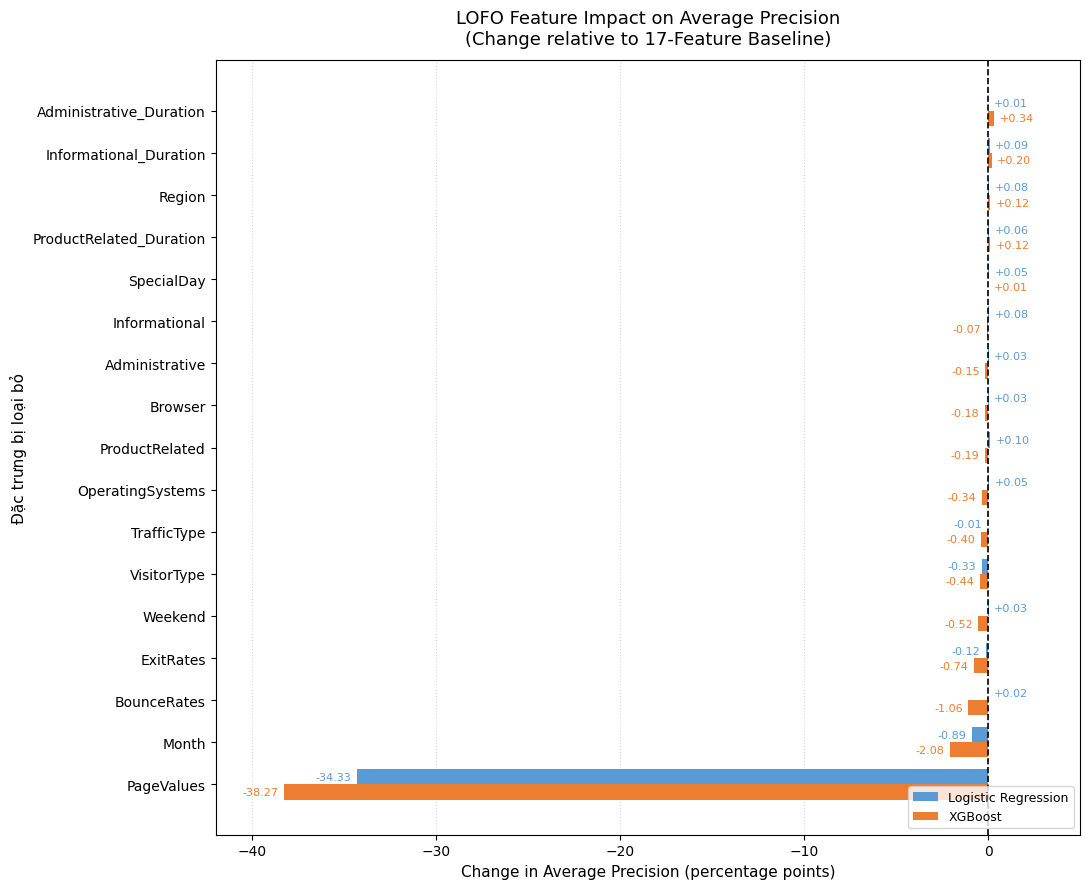

In [4]:

import matplotlib.pyplot as plt
import numpy as np

# Sắp xếp theo Delta XGBoost tăng dần
plot_df = lofo_df.sort_values(
    'XGB Delta (pp)', ascending=True
).reset_index(drop=True)

y = np.arange(len(plot_df))
bar_height = 0.36

fig, ax = plt.subplots(figsize=(11, 9))

# Đường tham chiếu Delta = 0
ax.axvline(
    0,
    color='black',
    linewidth=1.2,
    linestyle='--'
)

# Logistic Regression
ax.barh(
    y + bar_height / 2,
    plot_df['LR Delta (pp)'],
    height=bar_height,
    label='Logistic Regression',
    color='#5B9BD5'
)

# XGBoost
ax.barh(
    y - bar_height / 2,
    plot_df['XGB Delta (pp)'],
    height=bar_height,
    label='XGBoost',
    color='#ED7D31'
)

# Tên đặc trưng
ax.set_yticks(y)
ax.set_yticklabels(plot_df['Đặc trưng bị BỎ'])

# Hiển thị giá trị Delta ở cuối mỗi thanh
for i, (lr, xgb) in enumerate(zip(
    plot_df['LR Delta (pp)'],
    plot_df['XGB Delta (pp)']
)):
    ax.annotate(
        f'{lr:+.2f}',
        xy=(lr, y[i] + bar_height / 2),
        xytext=(-4 if lr < 0 else 4, 0),
        textcoords='offset points',
        ha='right' if lr < 0 else 'left',
        va='center',
        fontsize=8,
        color='#5B9BD5'
    )

    ax.annotate(
        f'{xgb:+.2f}',
        xy=(xgb, y[i] - bar_height / 2),
        xytext=(-4 if xgb < 0 else 4, 0),
        textcoords='offset points',
        ha='right' if xgb < 0 else 'left',
        va='center',
        fontsize=8,
        color='#ED7D31'
    )

# Trục và tiêu đề
ax.set_xlabel('Change in Average Precision (percentage points)', fontsize=11)
ax.set_ylabel('Đặc trưng bị loại bỏ', fontsize=11)
ax.set_title(
    'LOFO Feature Impact on Average Precision\n'
    '(Change relative to 17-Feature Baseline)',
    fontsize=13,
    pad=12
)

# Giới hạn trục X
ax.set_xlim(-42, 5)

ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.set_axisbelow(True)

ax.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

## 3. LOFO trên 16 Đặc trưng: Bóc tách Vai trò khi KHÔNG có `PageValues`
- Vì **77.86% số phiên có `PageValues = 0`**, việc kiểm tra LOFO khi bỏ hẳn `PageValues` giúp nhận diện chính xác những biến nào đang gánh vác việc phân loại cho phần lớn dữ liệu.

In [5]:
base_features_16 = [c for c in all_features if c != 'PageValues']
cv_splits = list(rskf.split(X_train[base_features_16], y_train))

def eval_subset_folds(feats):
    pre = get_preprocessor(feats)
    pipe_lr = Pipeline([('prep', pre), ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
    pipe_xgb = Pipeline([('prep', pre), ('clf', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1))])
    
    res_lr = cross_validate(pipe_lr, X_train[feats], y_train, cv=cv_splits, scoring=scorers_12fold, n_jobs=-1)
    res_xgb = cross_validate(pipe_xgb, X_train[feats], y_train, cv=cv_splits, scoring=scorers_12fold, n_jobs=-1)
    return res_lr, res_xgb

base_lr_16, base_xgb_16 = eval_subset_folds(base_features_16)
base_lr_ap_16 = base_lr_16['test_ap']
base_xgb_ap_16 = base_xgb_16['test_ap']

print("=== BASELINE: 16 FEATURES (KHÔNG CÓ PageValues) ===")
print(f"LR  AP: {base_lr_ap_16.mean() * 100:.2f} ± {base_lr_ap_16.std() * 100:.2f}%")
print(f"XGB AP: {base_xgb_ap_16.mean() * 100:.2f} ± {base_xgb_ap_16.std() * 100:.2f}%")

lofo16_records = []
EPSILON_PP = 0.05

for f in base_features_16:
    sub_features = [c for c in base_features_16 if c != f]
    res_lr, res_xgb = eval_subset_folds(sub_features)

    for model_name, baseline_scores, subset_scores in [
        ('LR', base_lr_ap_16, res_lr['test_ap']),
        ('XGB', base_xgb_ap_16, res_xgb['test_ap'])
    ]:
        delta_pp = (subset_scores - baseline_scores) * 100
        lofo16_records.append({
            'Model': model_name,
            'Feature bị bỏ': f,
            'Baseline AP (%)': baseline_scores.mean() * 100,
            'AP sau khi bỏ (%)': subset_scores.mean() * 100,
            'Delta AP mean (pp)': delta_pp.mean(),
            'Delta AP std (pp)': delta_pp.std(ddof=1),
            'Số fold giảm': int((delta_pp < -EPSILON_PP).sum()),
            'Số fold gần như không đổi': int((np.abs(delta_pp) <= EPSILON_PP).sum()),
            'Số fold tăng': int((delta_pp > EPSILON_PP).sum()),
        })

lofo16_df = pd.DataFrame(lofo16_records)
lr_lofo16 = lofo16_df[lofo16_df['Model'] == 'LR'].sort_values('Delta AP mean (pp)').reset_index(drop=True)
xgb_lofo16 = lofo16_df[lofo16_df['Model'] == 'XGB'].sort_values('Delta AP mean (pp)').reset_index(drop=True)

disp_cols = ['Feature bị bỏ', 'Baseline AP (%)', 'AP sau khi bỏ (%)', 'Delta AP mean (pp)', 'Delta AP std (pp)', 'Số fold giảm', 'Số fold tăng']

print("\n=== LOFO 16 FEATURES (KHÔNG CÓ PageValues): LOGISTIC REGRESSION ===")
display(lr_lofo16[disp_cols].round(2))

print("\n=== LOFO 16 FEATURES (KHÔNG CÓ PageValues): XGBOOST ===")
display(xgb_lofo16[disp_cols].round(2))

=== BASELINE: 16 FEATURES (KHÔNG CÓ PageValues) ===
LR  AP: 33.81 ± 1.99%
XGB AP: 33.26 ± 1.06%

=== LOFO 16 FEATURES (KHÔNG CÓ PageValues): LOGISTIC REGRESSION ===


,Feature bị bỏ,Baseline AP (%),AP sau khi bỏ (%),Delta AP mean (pp),Delta AP std (pp),Số fold giảm,Số fold tăng
0,Month,33.81,31.16,-2.65,0.83,12,0
1,ExitRates,33.81,32.76,-1.05,0.87,9,2
2,ProductRelated_Duration,33.81,33.05,-0.77,0.63,10,1
3,TrafficType,33.81,33.25,-0.56,0.74,10,2
4,VisitorType,33.81,33.72,-0.09,0.31,7,5
5,SpecialDay,33.81,33.74,-0.07,0.14,7,3
6,Administrative,33.81,33.84,0.03,0.20,4,5
7,Browser,33.81,33.84,0.03,0.41,5,5
8,Informational,33.81,33.85,0.04,0.15,3,2
9,OperatingSystems,33.81,33.86,0.05,0.45,5,6



=== LOFO 16 FEATURES (KHÔNG CÓ PageValues): XGBOOST ===


,Feature bị bỏ,Baseline AP (%),AP sau khi bỏ (%),Delta AP mean (pp),Delta AP std (pp),Số fold giảm,Số fold tăng
0,Month,33.26,29.82,-3.44,1.33,12,0
1,ProductRelated_Duration,33.26,32.01,-1.25,1.19,10,2
2,ExitRates,33.26,32.81,-0.46,1.68,6,5
3,BounceRates,33.26,32.85,-0.41,1.29,9,3
4,VisitorType,33.26,32.92,-0.34,1.31,7,5
5,Administrative,33.26,33.10,-0.16,1.60,7,4
6,SpecialDay,33.26,33.11,-0.15,1.42,7,5
7,TrafficType,33.26,33.27,0.00,1.19,6,6
8,OperatingSystems,33.26,33.36,0.10,1.09,5,7
9,Browser,33.26,33.40,0.14,2.02,6,6


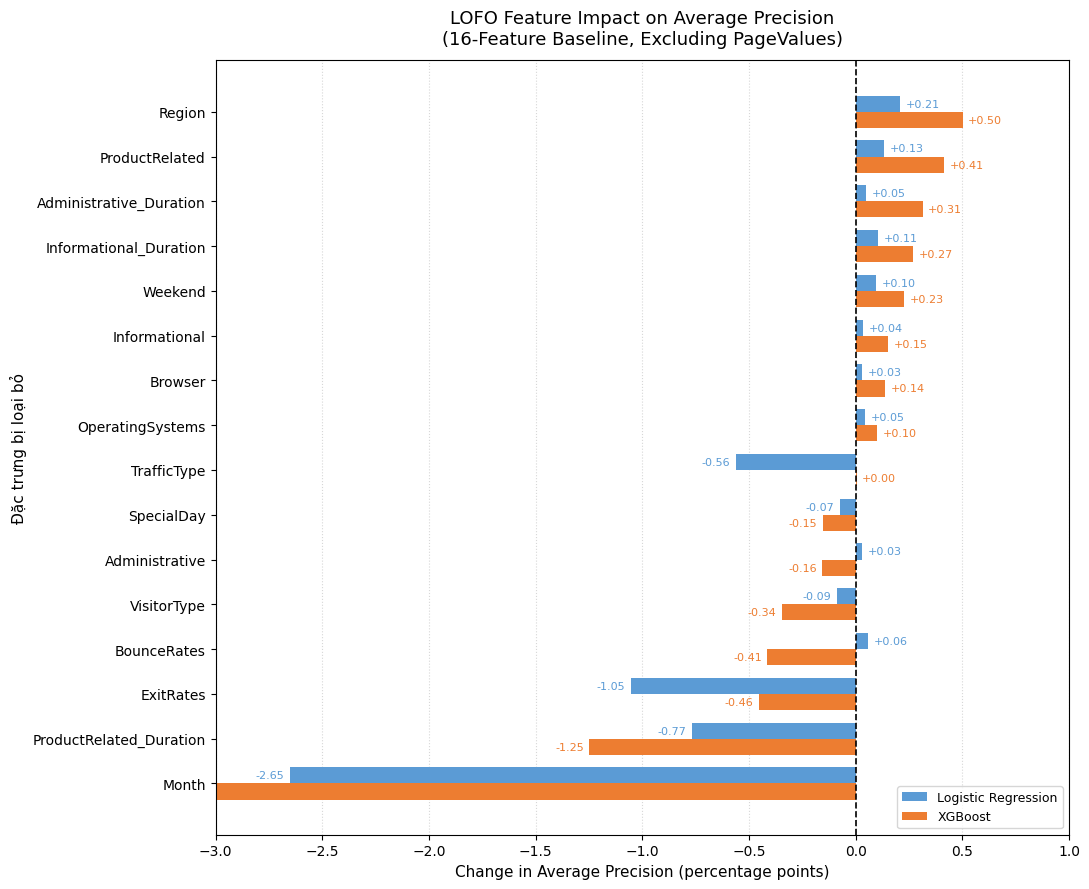

In [6]:
# 1. Sắp xếp theo Delta AP trung bình của XGBoost
plot_df = xgb_lofo16[['Feature bị bỏ', 'Delta AP mean (pp)']].merge(
    lr_lofo16[['Feature bị bỏ', 'Delta AP mean (pp)']],
    on='Feature bị bỏ',
    suffixes=('_XGB', '_LR')
).sort_values('Delta AP mean (pp)_XGB').reset_index(drop=True)

# 2. Thiết lập vị trí và kích thước cột
y = np.arange(len(plot_df))
bar_height = 0.36

fig, ax = plt.subplots(figsize=(11, 9))

# Đường mốc Delta = 0
ax.axvline(0, color='black', linewidth=1.2, linestyle='--')

# 3. Vẽ Delta AP của hai mô hình
ax.barh(
    y + bar_height / 2,
    plot_df['Delta AP mean (pp)_LR'],
    height=bar_height,
    label='Logistic Regression',
    color='#5B9BD5'
)

ax.barh(
    y - bar_height / 2,
    plot_df['Delta AP mean (pp)_XGB'],
    height=bar_height,
    label='XGBoost',
    color='#ED7D31'
)

# 4. Hiển thị giá trị Delta ở cuối mỗi thanh
for i, (lr, xgb) in enumerate(zip(
    plot_df['Delta AP mean (pp)_LR'],
    plot_df['Delta AP mean (pp)_XGB']
)):
    ax.annotate(
        f'{lr:+.2f}',
        xy=(lr, y[i] + bar_height / 2),
        xytext=(-4 if lr < 0 else 4, 0),
        textcoords='offset points',
        ha='right' if lr < 0 else 'left',
        va='center',
        fontsize=8,
        color='#5B9BD5'
    )

    ax.annotate(
        f'{xgb:+.2f}',
        xy=(xgb, y[i] - bar_height / 2),
        xytext=(-4 if xgb < 0 else 4, 0),
        textcoords='offset points',
        ha='right' if xgb < 0 else 'left',
        va='center',
        fontsize=8,
        color='#ED7D31'
    )

# 5. Nhãn trục
ax.set_yticks(y)
ax.set_yticklabels(plot_df['Feature bị bỏ'])

ax.set_xlabel('Change in Average Precision (percentage points)', fontsize=11)
ax.set_ylabel('Đặc trưng bị loại bỏ', fontsize=11)

# 6. Tiêu đề
ax.set_title(
    'LOFO Feature Impact on Average Precision\n'
    '(16-Feature Baseline, Excluding PageValues)',
    fontsize=13,
    pad=12
)

# 7. Giới hạn trục X
ax.set_xlim(-3, 1)

# 8. Hiển thị
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.set_axisbelow(True)
ax.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()